# LAB 04 — Text Classification

Dataset: IMDb (50.000 reviews có nhãn). Gộp tập `train` và `test` gốc, sau đó chia lại theo tỷ lệ khoảng 70% / 15% / 15%.

Notebook sử dụng các hàm từ `preprocessing.py`. Trong Colab, đặt `aclImdb_v1.tar.gz` và `preprocessing.py` ở `/content/` trước khi chạy.
**Tính tái lập:** `random_state=42` cố định cách chia dữ liệu. Word2Vec dùng `seed=42` nhưng có `workers=2` nên có thể chênh lệch nhẹ giữa các lần chạy; thời gian chạy cũng phụ thuộc môi trường. Nhận xét số liệu nên đối chiếu với output của cùng lần chạy.


In [4]:
!pip install gensim

## 1. Import

In [5]:
import hashlib
import re
import tarfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

from preprocessing import clean_text, tfidf_features, train_classifier, predict, evaluate

pd.set_option("display.max_colwidth", 120)

## 2. Đọc IMDb và gộp 50.000 reviews

Dùng cách đọc file theo hai thư mục `train/test` và hai nhãn `neg/pos`. Không lấy thư mục `unsup` vì không có nhãn.

In [6]:
import tarfile
from pathlib import Path
import pandas as pd

archive = Path("/content/aclImdb_v1.tar.gz")
root = Path("/content/w4/aclImdb")

def count_files():
    return [
        len(list((root / split / folder).glob("*.txt")))
        for split in ["train", "test"]
        for folder in ["neg", "pos"]
    ]

if count_files() != [12500] * 4:
    print("Đang giải nén dữ liệu...")

    if not archive.exists():
        raise FileNotFoundError(f"Không tìm thấy {archive}")

    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall("/content/w4", filter="data")

counts = count_files()

for name, count in zip(
    ["train/neg", "train/pos", "test/neg", "test/pos"],
    counts
):
    print(f"{name}: {count}")

if counts != [12500] * 4:
    raise ValueError("Dữ liệu chưa đủ 50.000 reviews. Kiểm tra file tar.gz")

def load_data(split):
    texts = []
    labels = []

    for label, folder in [(0, "neg"), (1, "pos")]:
        for file in sorted((root / split / folder).glob("*.txt")):
            texts.append(file.read_text(encoding="utf-8"))
            labels.append(label)

    return texts, labels

x_train_old, y_train_old = load_data("train")
x_test_old, y_test_old = load_data("test")

data = pd.DataFrame({
    "text": x_train_old + x_test_old,
    "label": y_train_old + y_test_old
})

print("Total:", len(data))
print("Train gốc:", len(x_train_old))
print("Test gốc:", len(x_test_old))

display(data.head())

Đang giải nén dữ liệu...
train/neg: 12500
train/pos: 12500
test/neg: 12500
test/pos: 12500
Total: 50000
Train gốc: 25000
Test gốc: 25000


,text,label
0,Story of a man who has unnatural feelings for a pig. Starts out with a opening scene that is a terrific example of a...,0
1,Airport '77 starts as a brand new luxury 747 plane is loaded up with valuable paintings & such belonging to rich bus...,0
2,This film lacked something I couldn't put my finger on at first: charisma on the part of the leading actress. This i...,0
3,"Sorry everyone,,, I know this is supposed to be an ""art"" film,, but wow, they should have handed out guns at the scr...",0
4,When I was little my parents took me along to the theater to see Interiors. It was one of many movies I watched with...,0


## 3. Experiment 1 — Dataset inspection

Kiểm tra số mẫu, số lớp, phân phối nhãn, độ dài review, dữ liệu thiếu và review trùng trước khi train.

In [7]:
data["length"] = data["text"].map(lambda x: len(clean_text(x).split()))
data["group"] = data["text"].map(
    lambda x: hashlib.md5(clean_text(x).encode("utf-8")).hexdigest()
)

print("Classes:", data["label"].nunique())
print("Missing text:", data["text"].isna().sum())
print("Empty text:", data["text"].str.strip().eq("").sum())
print("Missing labels:", data["label"].isna().sum())
print("Duplicate reviews:", data.duplicated("group").sum())
print("Conflicting labels:", (data.groupby("group")["label"].nunique() > 1).sum())

display(data["length"].describe())

distribution = data["label"].value_counts().sort_index()
display(pd.DataFrame({
    "class": ["Negative", "Positive"],
    "count": distribution.values,
    "percentage": (distribution.values / len(data) * 100).round(2)
}))

Classes: 2
Missing text: 0
Empty text: 0
Missing labels: 0
Duplicate reviews: 422
Conflicting labels: 0


,length
count,50000.000000
mean,228.865940
std,169.589105
min,4.000000
25%,125.000000
50%,171.000000
75%,278.000000
max,2459.000000


,class,count,percentage
0,Negative,25000,50.0
1,Positive,25000,50.0


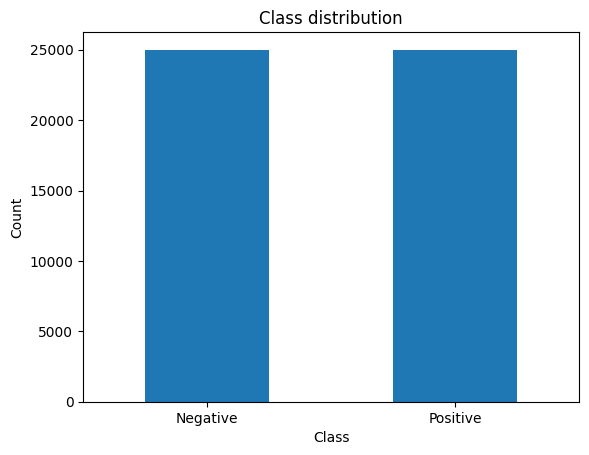

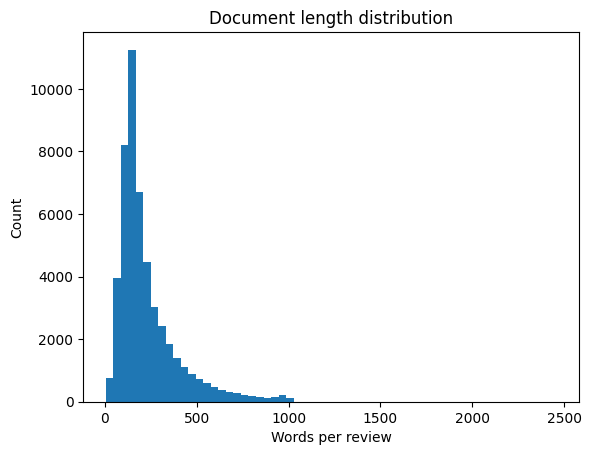

In [8]:
distribution.rename({0: "Negative", 1: "Positive"}).plot.bar(rot=0)
plt.title("Class distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

plt.hist(data["length"], bins=60)
plt.title("Document length distribution")
plt.xlabel("Words per review")
plt.ylabel("Count")
plt.show()

**Câu hỏi: Dataset có bị mất cân bằng lớp không?**

**Trả lời:** Không. IMDb có 50.000 review, gồm 25.000 Negative và 25.000 Positive, mỗi lớp chiếm 50%. Không có văn bản rỗng hay nhãn thiếu. Có 422 review trùng theo nội dung đã làm sạch, độ dài trung bình khoảng 229 từ.

## 4. Chia train / validation / test và kiểm tra data leakage

Chia các nhóm review có nội dung giống nhau vào cùng một tập để tránh review trùng xuất hiện ở cả train và test. Vì chia theo nhóm nên số dòng có thể lệch nhẹ so với 35.000 / 7.500 / 7.500, nhưng tổng số review vẫn là 50.000. Chỉ fit các biểu diễn trên train.

In [9]:
group_labels = data.groupby("group")["label"].first()

train_groups, temp_groups = train_test_split(
    group_labels.index.to_numpy(),
    test_size=0.3,
    random_state=42,
    stratify=group_labels.to_numpy()
)

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=0.5,
    random_state=42,
    stratify=group_labels.loc[temp_groups].to_numpy()
)

train = data[data["group"].isin(train_groups)].copy()
val = data[data["group"].isin(val_groups)].copy()
test = data[data["group"].isin(test_groups)].copy()

assert len(train) + len(val) + len(test) == 50000
assert not (set(train["group"]) & set(val["group"]))
assert not (set(train["group"]) & set(test["group"]))
assert not (set(val["group"]) & set(test["group"]))

X_train, y_train = train["text"], train["label"]
X_val, y_val = val["text"], val["label"]
X_test, y_test = test["text"], test["label"]

split_table = pd.DataFrame([
    [name, len(part), round(len(part) / len(data) * 100, 2),
     int((part["label"] == 0).sum()), int((part["label"] == 1).sum())]
    for name, part in [("Train", train), ("Validation", val), ("Test", test)]
], columns=["Split", "Count", "Percentage", "Negative", "Positive"])

display(split_table)

,Split,Count,Percentage,Negative,Positive
0,Train,35000,70.00,17503,17497
1,Validation,7507,15.01,3752,3755
2,Test,7493,14.99,3745,3748


**Câu hỏi: Vì sao fit TF-IDF trước khi chia dữ liệu gây data leakage?**

**Trả lời:** Vì vocabulary và IDF sẽ học cả thông tin từ validation/test. Khi đó tập đánh giá không còn độc lập, làm kết quả thiếu khách quan.

**Cách xử lý trong notebook:** Chia dữ liệu trước, giữ các review trùng trong cùng một tập. Train có 35.000 mẫu, validation có 7.507 và test có 7.493. TF-IDF và Word2Vec chỉ fit trên train; validation/test chỉ được transform.

## 5. Core implementation và baseline — TF-IDF + Logistic Regression

TF-IDF dùng `fit_transform` trên train; validation/test chỉ dùng `transform`. Đánh giá mô hình trên validation khi so sánh các phương án.

In [10]:
def add_result(name, representation, classifier, y_pred, vocab_size, train_time):
    metrics = evaluate(y_val, y_pred)
    return {
        "Model": name,
        "Representation": representation,
        "Classifier": classifier,
        "Split": "Validation",
        "Vocabulary": vocab_size,
        "Training time (s)": round(train_time, 2),
        "Accuracy": metrics["accuracy"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "F1": metrics["f1"]
    }


results = []
start = time.perf_counter()

vectorizer_uni, train_uni, val_uni, test_uni = tfidf_features(
    X_train, X_val, X_test,
    ngram_range=(1, 1), min_df=3, max_features=100000
)
prep_uni = time.perf_counter() - start
model_uni = train_classifier(train_uni, y_train)
time_uni = time.perf_counter() - start

pred_uni = predict(model_uni, val_uni)
results.append(add_result(
    "TF-IDF Unigram + LR", "TF-IDF", "Logistic Regression",
    pred_uni, len(vectorizer_uni.vocabulary_), time_uni
))

display(pd.DataFrame(results))

,Model,Representation,Classifier,Split,Vocabulary,Training time (s),Accuracy,Precision,Recall,F1
0,TF-IDF Unigram + LR,TF-IDF,Logistic Regression,Validation,41363,24.38,0.889836,0.889879,0.889834,0.889833


**Câu hỏi: Baseline TF-IDF + Logistic Regression cho kết quả như thế nào?**

**Trả lời:** Accuracy, Precision, Recall, F1, số features và thời gian huấn luyện được ghi trong bảng validation ngay phía trên. Đây là mô hình baseline để so sánh với các phương án khác. Thời gian chạy có thể thay đổi giữa các phiên Colab.


## 6. Experiment 3 — Average Word2Vec + Logistic Regression

Huấn luyện Word2Vec **chỉ từ review của train**. Biểu diễn mỗi review bằng trung bình vector các từ; với từ không có trong vocabulary thì bỏ qua.

In [11]:
def tokenize(text):
    return re.findall(r"\b\w+\b", clean_text(text))


def average_vectors(texts, w2v):
    vectors = np.zeros((len(texts), w2v.vector_size), dtype=np.float32)

    for i, text in enumerate(texts):
        words = [w2v.wv[word] for word in tokenize(text) if word in w2v.wv]
        if words:
            vectors[i] = np.mean(words, axis=0)

    return vectors


start = time.perf_counter()
train_tokens = [tokenize(text) for text in X_train]

w2v = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=2,
    epochs=5,
    seed=42
)

train_w2v = average_vectors(X_train, w2v)
val_w2v = average_vectors(X_val, w2v)
model_w2v = train_classifier(train_w2v, y_train)
time_w2v = time.perf_counter() - start

pred_w2v = predict(model_w2v, val_w2v)
results.append(add_result(
    "Avg Word2Vec + LR", "Average Word2Vec", "Logistic Regression",
    pred_w2v, len(w2v.wv), time_w2v
))

display(pd.DataFrame(results))

,Model,Representation,Classifier,Split,Vocabulary,Training time (s),Accuracy,Precision,Recall,F1
0,TF-IDF Unigram + LR,TF-IDF,Logistic Regression,Validation,41363,24.38,0.889836,0.889879,0.889834,0.889833
1,Avg Word2Vec + LR,Average Word2Vec,Logistic Regression,Validation,54741,128.92,0.816172,0.816220,0.816169,0.816164


**Câu hỏi: Tại sao hai representation cho kết quả khác nhau? Average Word2Vec có chắc chắn tốt hơn TF-IDF không?**

**Trả lời:** Không. TF-IDF giữ các từ đặc trưng cho cảm xúc; Average Word2Vec lấy trung bình các vector nên có thể làm yếu tín hiệu cảm xúc và không giữ thứ tự từ. Trong output đang lưu, TF-IDF unigram có F1 cao hơn Average Word2Vec. Các giá trị F1, vocabulary và thời gian chính xác được hiển thị trong bảng trên; kết quả Word2Vec có thể chênh lệch nhẹ khi chạy lại.


## 7. Experiment 3 — TF-IDF + Linear SVM

So sánh thêm một classifier trên cùng biểu diễn TF-IDF unigram.

In [12]:
start = time.perf_counter()
model_svm = LinearSVC(random_state=42)
model_svm.fit(train_uni, y_train)
time_svm = time.perf_counter() - start + prep_uni

pred_svm = model_svm.predict(val_uni)
results.append(add_result(
    "TF-IDF Unigram + SVM", "TF-IDF", "Linear SVM",
    pred_svm, len(vectorizer_uni.vocabulary_), time_svm
))

display(pd.DataFrame(results))

,Model,Representation,Classifier,Split,Vocabulary,Training time (s),Accuracy,Precision,Recall,F1
0,TF-IDF Unigram + LR,TF-IDF,Logistic Regression,Validation,41363,24.38,0.889836,0.889879,0.889834,0.889833
1,Avg Word2Vec + LR,Average Word2Vec,Logistic Regression,Validation,54741,128.92,0.816172,0.816220,0.816169,0.816164
2,TF-IDF Unigram + SVM,TF-IDF,Linear SVM,Validation,41363,20.81,0.888770,0.888801,0.888769,0.888768


**Câu hỏi: Đổi Logistic Regression sang Linear SVM có cải thiện rõ không?**

**Trả lời:** Với cùng TF-IDF unigram, F1 của SVM và Logistic Regression gần nhau ở lần chạy này. So sánh hai hàng tương ứng trong bảng; không thể kết luận SVM luôn tốt hơn hay kém hơn trên mọi cấu hình.


## Vì sao hai representation tạo ra kết quả khác nhau?

Không chỉ so sánh Accuracy, cần xem **cách mỗi representation lưu giữ thông tin của văn bản**.

| Đặc điểm | TF-IDF | Average Word2Vec |
|---|---|---|
| Dạng vector | **Sparse**: nhiều phần tử bằng 0 | **Dense**: 100 chiều trong thí nghiệm |
| Thông tin chính | **Lexical**: ghi nhận từ và cụm từ | **Semantic**: biểu diễn quan hệ giữa các từ |
| Điểm mạnh | Giữ riêng các term như `excellent`, `worst` | Các từ gần nghĩa có thể có vector gần nhau |
| Thứ tự từ | Unigram không giữ thứ tự; bigram giữ cặp từ liên tiếp | Phép lấy trung bình không giữ thứ tự |
| Hạn chế | Khó xử lý đa nghĩa và ngữ cảnh dài | Mỗi từ có một vector cố định; averaging có thể làm mờ từ phủ định và từ thể hiện cảm xúc |

**Trả lời:** Với IMDb, nhiều từ hoặc cụm từ là tín hiệu mạnh về cảm xúc nên TF-IDF có lợi thế. Average Word2Vec gom nhiều từ thành một vector chung, có thể mất thông tin quan trọng. Vì thế hai mô hình cùng dùng Logistic Regression vẫn cho kết quả khác nhau.

**Đối chiếu thực nghiệm:** Xem F1 validation của hai mô hình trong bảng ở trên. Trong lần chạy đang lưu, TF-IDF unigram tốt hơn Average Word2Vec. Word2Vec dùng vector **100 chiều**, còn số từ trong vocabulary là đại lượng khác, không phải số chiều. Không kết luận rằng TF-IDF luôn tốt hơn Word2Vec.


## Experiment 4: Word order

Kiểm tra hai câu `this movie is good` và `this movie is not good`. Sau đó đảo vị trí các từ của cùng một câu để kiểm tra xem cách biểu diễn có giữ thông tin thứ tự từ không.

In [13]:
sentences = ["this movie is good", "this movie is not good"]

order_results = pd.DataFrame({
    "Text": sentences,
    "TF-IDF unigram + LR": predict(model_uni, vectorizer_uni.transform(sentences)),
    "Avg Word2Vec + LR": predict(model_w2v, average_vectors(sentences, w2v))
})
display(order_results.replace({0: "Negative", 1: "Positive"}))

reordered = ["this movie is good", "good is movie this"]
a = vectorizer_uni.transform(reordered).toarray()
b = average_vectors(reordered, w2v)
print("TF-IDF unigram không phân biệt thứ tự:", np.allclose(a[0], a[1]))
print("Average Word2Vec không phân biệt thứ tự:", np.allclose(b[0], b[1]))

,Text,TF-IDF unigram + LR,Avg Word2Vec + LR
0,this movie is good,Positive,Positive
1,this movie is not good,Positive,Positive


TF-IDF unigram không phân biệt thứ tự: True
Average Word2Vec không phân biệt thứ tự: True


**Câu hỏi: Average Word2Vec có hiểu được vai trò của `not` không?**

**Trả lời:** Average Word2Vec chỉ lấy trung bình các vector từ, nên không biểu diễn trực tiếp việc `not` phủ định `good`. Khi đảo vị trí những từ giống nhau, vector trung bình gần như không đổi. Trong kết quả đã chạy, cả **TF-IDF unigram** và **Average Word2Vec** đều dự đoán **Positive** cho hai câu trên. Vì vậy, hai cách biểu diễn này chưa xử lý tốt ví dụ phủ định này; không nên kết luận chung rằng chúng luôn dự đoán sai mọi câu phủ định.

## Experiment 5: n-gram features

So sánh **TF-IDF unigram** và **TF-IDF unigram + bigram** cùng Logistic Regression; giữ nguyên tập train/validation và các tham số `min_df`, `max_features` để so sánh.

In [14]:
start = time.perf_counter()
vectorizer_bi, train_bi, val_bi, test_bi = tfidf_features(
    X_train, X_val, X_test,
    ngram_range=(1, 2), min_df=3, max_features=100000
)
model_bi = train_classifier(train_bi, y_train)
time_bi = time.perf_counter() - start

pred_bi = predict(model_bi, val_bi)
results.append(add_result(
    "TF-IDF Uni+Bigram + LR", "TF-IDF Uni+Bigram", "Logistic Regression",
    pred_bi, len(vectorizer_bi.vocabulary_), time_bi
))

comparison = pd.DataFrame(results)
display(comparison.round(4))

display(comparison[comparison["Model"].isin([
    "TF-IDF Unigram + LR", "TF-IDF Uni+Bigram + LR"
])][["Model", "Vocabulary", "F1", "Training time (s)"]])

,Model,Representation,Classifier,Split,Vocabulary,Training time (s),Accuracy,Precision,Recall,F1
0,TF-IDF Unigram + LR,TF-IDF,Logistic Regression,Validation,41363,24.38,0.8898,0.8899,0.8898,0.8898
1,Avg Word2Vec + LR,Average Word2Vec,Logistic Regression,Validation,54741,128.92,0.8162,0.8162,0.8162,0.8162
2,TF-IDF Unigram + SVM,TF-IDF,Linear SVM,Validation,41363,20.81,0.8888,0.8888,0.8888,0.8888
3,TF-IDF Uni+Bigram + LR,TF-IDF Uni+Bigram,Logistic Regression,Validation,100000,48.84,0.8988,0.8989,0.8988,0.8988


,Model,Vocabulary,F1,Training time (s)
0,TF-IDF Unigram + LR,41363,0.889833,24.38
3,TF-IDF Uni+Bigram + LR,100000,0.898755,48.84


**Câu hỏi: Vì sao bigram có thể giúp classification nhưng đồng thời làm feature space lớn hơn?**

**Trả lời:** Bigram tạo feature cho hai từ đứng cạnh nhau, như `not good` hoặc `very good`, nên giúp giữ một phần ngữ cảnh, đặc biệt là phủ định. Mỗi cặp từ lại tạo thêm một feature, làm vocabulary lớn hơn và có thể tăng thời gian xử lý.

**Đối chiếu thực nghiệm:** So sánh hai hàng *TF-IDF Unigram + LR* và *TF-IDF Uni+Bigram + LR* ngay phía trên theo F1, Vocabulary và Training time. Mô hình bigram được giới hạn tối đa `max_features=100000`, nên số features thực tế có thể chạm ngưỡng này.


### Kiểm tra lại hai câu sau khi thêm bigram

Dùng cùng hai câu trong Experiment 4, lần này so sánh thêm mô hình TF-IDF unigram + bigram vừa được huấn luyện.

In [15]:
sentences = ["this movie is good", "this movie is not good"]

word_order = pd.DataFrame({
    "Text": sentences,
    "TF-IDF + LR": predict(model_uni, vectorizer_uni.transform(sentences)),
    "Avg Word2Vec + LR": predict(model_w2v, average_vectors(sentences, w2v)),
    "Unigram+Bigram + LR": predict(model_bi, vectorizer_bi.transform(sentences))
})

display(word_order)

,Text,TF-IDF + LR,Avg Word2Vec + LR,Unigram+Bigram + LR
0,this movie is good,1,1,1
1,this movie is not good,1,1,0


**Câu hỏi: Thêm bigram có giúp phân biệt `good` và `not good` không?**

**Trả lời:** Trong kết quả của hai câu minh họa phía trên, mô hình TF-IDF unigram + bigram dự đoán `this movie is good` là Positive và `this movie is not good` là Negative. TF-IDF unigram và Average Word2Vec dự đoán Positive cho cả hai câu. Bigram giữ được cụm `not good`, nhưng đây chỉ là ví dụ cụ thể, không chứng minh mô hình hiểu đúng mọi câu phủ định.


## Tổng hợp và chọn mô hình trên validation

Chỉ dùng F1 của validation để lựa chọn mô hình. Không sử dụng test để chọn mô hình hay điều chỉnh tham số.

In [16]:
validation_results = pd.DataFrame(results).sort_values("F1", ascending=False)
display(validation_results.round(4))

best_name = validation_results.iloc[0]["Model"]
print("Selected on validation:", best_name)

,Model,Representation,Classifier,Split,Vocabulary,Training time (s),Accuracy,Precision,Recall,F1
3,TF-IDF Uni+Bigram + LR,TF-IDF Uni+Bigram,Logistic Regression,Validation,100000,48.84,0.8988,0.8989,0.8988,0.8988
0,TF-IDF Unigram + LR,TF-IDF,Logistic Regression,Validation,41363,24.38,0.8898,0.8899,0.8898,0.8898
2,TF-IDF Unigram + SVM,TF-IDF,Linear SVM,Validation,41363,20.81,0.8888,0.8888,0.8888,0.8888
1,Avg Word2Vec + LR,Average Word2Vec,Logistic Regression,Validation,54741,128.92,0.8162,0.8162,0.8162,0.8162


Selected on validation: TF-IDF Uni+Bigram + LR


**Câu hỏi: Nên chọn mô hình nào và dựa trên tập dữ liệu nào?**

**Trả lời:** Chọn mô hình có **F1 trên validation cao nhất**, được in ở dòng `Selected on validation` phía trên. Trong lần chạy đang lưu, đó là TF-IDF unigram + bigram + Logistic Regression. Không dùng test để quyết định chọn mô hình hoặc chỉnh tham số.


## Đánh giá test một lần và confusion matrix

Sau khi chọn mô hình trên validation, mới đánh giá với test chưa từng dùng để chọn mô hình.

In [17]:
models = {
    "TF-IDF Unigram + LR": (model_uni, test_uni),
    "Avg Word2Vec + LR": (model_w2v, None),
    "TF-IDF Unigram + SVM": (model_svm, test_uni),
    "TF-IDF Uni+Bigram + LR": (model_bi, test_bi)
}

best_model, test_features = models[best_name]
if best_name == "Avg Word2Vec + LR":
    test_features = average_vectors(X_test, w2v)

y_pred = best_model.predict(test_features)
test_scores = evaluate(y_test, y_pred)

print("Test metrics:")
display(pd.DataFrame([{k: v for k, v in test_scores.items() if k != "confusion_matrix"}]).round(4))
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], zero_division=0))

selected_row = validation_results.iloc[0].to_dict()
selected_row.update({
    "Split": "Test",
    "Accuracy": test_scores["accuracy"],
    "Precision": test_scores["precision"],
    "Recall": test_scores["recall"],
    "F1": test_scores["f1"]
})

all_results = pd.concat([
    pd.DataFrame(results), pd.DataFrame([selected_row])
], ignore_index=True)
all_results.to_csv("/content/results.csv", index=False)
display(all_results.round(4))

Test metrics:


,accuracy,precision,recall,f1
0,0.9035,0.9036,0.9035,0.9035


              precision    recall  f1-score   support

    Negative       0.91      0.90      0.90      3745
    Positive       0.90      0.91      0.90      3748

    accuracy                           0.90      7493
   macro avg       0.90      0.90      0.90      7493
weighted avg       0.90      0.90      0.90      7493



,Model,Representation,Classifier,Split,Vocabulary,Training time (s),Accuracy,Precision,Recall,F1
0,TF-IDF Unigram + LR,TF-IDF,Logistic Regression,Validation,41363,24.38,0.8898,0.8899,0.8898,0.8898
1,Avg Word2Vec + LR,Average Word2Vec,Logistic Regression,Validation,54741,128.92,0.8162,0.8162,0.8162,0.8162
2,TF-IDF Unigram + SVM,TF-IDF,Linear SVM,Validation,41363,20.81,0.8888,0.8888,0.8888,0.8888
3,TF-IDF Uni+Bigram + LR,TF-IDF Uni+Bigram,Logistic Regression,Validation,100000,48.84,0.8988,0.8989,0.8988,0.8988
4,TF-IDF Uni+Bigram + LR,TF-IDF Uni+Bigram,Logistic Regression,Test,100000,48.84,0.9035,0.9036,0.9035,0.9035


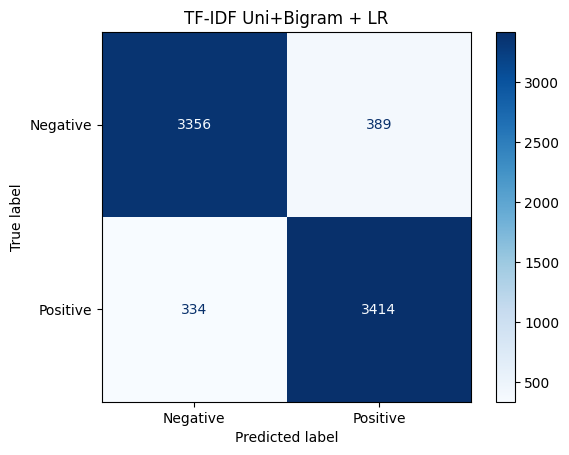

In [18]:
cm = test_scores["confusion_matrix"]
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(values_format="d", cmap="Blues")

plt.title(best_name)
plt.savefig("/content/confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

**Câu hỏi: Lớp nào bị nhầm nhiều nhất? False Positive hay False Negative nhiều hơn? Metric nào phản ánh lỗi đó?**

**Trả lời:** Theo confusion matrix đang lưu, **False Positive (Negative → Positive)** nhiều hơn **False Negative (Positive → Negative)**, nên lớp Negative bị nhầm nhiều hơn. Recall riêng của lớp Negative thấp hơn lớp Positive, thể hiện trong `classification_report`.

**Đánh giá:** Xem Accuracy, Precision, Recall, F1 (trung bình macro) trong bảng test phía trên. Không nên chỉ xem accuracy vì có thể bỏ qua lỗi của từng lớp. Nếu chạy lại và ma trận thay đổi, cần đối chiếu và cập nhật nhận xét này.

## Error analysis — 3 mẫu đúng, 3 mẫu sai

Chọn các mẫu từ test để xem nhãn thật, dự đoán và nhận xét. Bảng bên dưới có nhận xét ngắn; nguyên nhân sai chỉ là giả thuyết từ đoạn văn bản được xem, cần đối chiếu review đầy đủ.

In [19]:
examples = test[["text", "label"]].copy()
examples["predicted"] = y_pred

correct = examples[examples["label"] == examples["predicted"]].sample(
    n=min(3, (examples["label"] == examples["predicted"]).sum()),
    random_state=42
)
wrong = examples[examples["label"] != examples["predicted"]].sample(
    n=min(3, (examples["label"] != examples["predicted"]).sum()),
    random_state=42
)

correct["Type"] = "Correct"
wrong["Type"] = "Incorrect"
error_table = pd.concat([correct, wrong]).rename(columns={
    "text": "Text", "label": "True", "predicted": "Predicted"
})
error_table["Analysis"] = ""
sample_notes = {
    'I love low budget independent films': "Đúng (Negative): đầu bài có 'love', 'high hopes' nhưng sau đó chê phim 'static'; cần xem toàn bài để chắc chắn.",
    'UK-born Australian helmer Alex Frayne': 'Đúng (Positive): đoạn mở đầu đánh giá phim gây chú ý; cần đọc toàn bài để xác định các dấu hiệu tích cực.',
    'By the standards of Hollywood this movie': 'Đúng (Negative): đoạn đầu chủ yếu mô tả cách làm phim; tín hiệu tiêu cực chưa rõ, cần đọc toàn bài.',
    "If in the 90's you're adapting a book": "Sai (Positive thành Negative): 'bloody', 'not' và giọng phàn nàn có thể khiến model nghiêng về Negative.",
    'Well, "built" Doris Day': "Sai (Negative thành Positive): 'falls in love' nói về cốt truyện, không hẳn là đánh giá tích cực về phim.",
    'Worst horror film ever but funniest': "Sai (Positive thành Negative): trộn 'worst', 'cheap' với 'funniest', 'you have got to see'; có thể gây nhầm vì sắc thái hài hước.",
}
for idx, row in error_table.iterrows():
    for prefix, note in sample_notes.items():
        if row["Text"].startswith(prefix):
            error_table.at[idx, "Analysis"] = note
            break

error_table = error_table[["Type", "Text", "True", "Predicted", "Analysis"]]

if len(correct) < 3 or len(wrong) < 3:
    print("Warning: Not enough correct or incorrect samples for 3 + 3 examples")

display(error_table.assign(Text=error_table["Text"].str.slice(0, 250)))
error_table.to_csv("/content/error_samples.csv", index=False)

with open("/content/error_analysis.md", "w", encoding="utf-8") as f:
    f.write("# Error analysis\n\n")
    f.write("| Type | Text | True | Predicted | Analysis |\n")
    f.write("|---|---|---|---|---|\n")
    for _, row in error_table.iterrows():
        sample = row["Text"].replace("\n", " ").replace("|", "\\|")[:250]
        f.write(f"| {row['Type']} | {sample} | {row['True']} | {row['Predicted']} | {row['Analysis']} |\n")

,Type,Text,True,Predicted,Analysis
1368,Correct,I love low budget independent films and had high hopes for this one. But this film is static. Never mind the product...,0,0,"Đúng (Negative): đầu bài có 'love', 'high hopes' nhưng sau đó chê phim 'static'; cần xem toàn bài để chắc chắn."
38699,Correct,"UK-born Australian helmer Alex Frayne calls for attention with his strange, necessitating a meticulous read, visuall...",1,1,Đúng (Positive): đoạn mở đầu đánh giá phim gây chú ý; cần đọc toàn bài để xác định các dấu hiệu tích cực.
33698,Correct,By the standards of Hollywood this movie was filmed and edited as Hollywood movies are and therefore looked like a m...,0,0,"Đúng (Negative): đoạn đầu chủ yếu mô tả cách làm phim; tín hiệu tiêu cực chưa rõ, cần đọc toàn bài."
22477,Incorrect,"If in the 90's you're adapting a book written in the 50's, set the bloody thing in the 50's and not the '90's. See, ...",1,0,"Sai (Positive thành Negative): 'bloody', 'not' và giọng phàn nàn có thể khiến model nghiêng về Negative."
34924,Incorrect,"Well, ""built"" Doris Day (as Ethel S. ""Dynamite"" Jackson) is mistaken for thespian Ethel Barrymore, and falls in love...",0,1,"Sai (Negative thành Positive): 'falls in love' nói về cốt truyện, không hẳn là đánh giá tích cực về phim."
40149,Incorrect,Worst horror film ever but funniest film ever rolled in one you have got to see this film it is so cheap it is unbel...,1,0,"Sai (Positive thành Negative): trộn 'worst', 'cheap' với 'funniest', 'you have got to see'; có thể gây nhầm vì sắc t..."


**Câu hỏi: Các review nào được dự đoán đúng/sai và có thể do đâu?**

**Trả lời:** Bảng `error_table` phía trên chứa **3 review dự đoán đúng** và **3 review dự đoán sai**, kèm cột `Analysis` với nhận xét cho từng trường hợp. Review có thể khiến mô hình nhầm vì từ thể hiện cảm xúc xuất hiện trong ngữ cảnh khác, câu phủ định, hoặc sắc thái vừa khen vừa chê.

**Lưu ý:** Nhận xét trong cột `Analysis` là giả thuyết từ những review đã chọn. Chỉ 250 ký tự đầu được hiển thị; cần đọc toàn văn trong `error_table` hoặc `error_samples.csv`. Nếu chọn lại mẫu sau khi huấn luyện, phải kiểm tra lại các nhận xét cho đúng với mẫu mới.


## Inspect model weights — TF-IDF + Logistic Regression

Xem top feature có hệ số cao và thấp đối với class `1 = Positive` ở mô hình baseline.

In [20]:
weights = pd.DataFrame({
    "Feature": vectorizer_uni.get_feature_names_out(),
    "Weight": model_uni.coef_[0]
})

top_negative = weights.nsmallest(15, "Weight")
top_positive = weights.nlargest(15, "Weight")

display(top_negative)
display(top_positive)

pd.concat([
    top_negative.assign(Class="Negative"),
    top_positive.assign(Class="Positive")
]).to_csv("/content/top_features.csv", index=False)

,Feature,Weight
40857,worst,-10.679615
2893,bad,-9.063301
2773,awful,-7.716274
40055,waste,-7.161195
4507,boring,-6.882880
36741,terrible,-6.309728
27995,poor,-6.102522
25349,nothing,-5.452298
17689,horrible,-5.140404
40844,worse,-4.853655


,Feature,Weight
16002,great,8.722392
12845,excellent,7.235280
3723,best,5.780762
27107,perfect,5.501917
40750,wonderful,5.031404
21991,loved,4.807347
1494,amazing,4.511650
4877,brilliant,4.256479
14849,fun,4.200224
37281,today,4.150678


**Câu hỏi: Các feature có trọng số lớn có thực sự có ý nghĩa với bài toán không?**

**Trả lời:** Phần lớn là có. Các từ như `worst`, `bad`, `awful`, `boring` thiên về Negative; `great`, `excellent`, `best`, `wonderful` thiên về Positive. Tuy nhiên, một số từ như `today`, `script`, `well` phụ thuộc ngữ cảnh. Trọng số cho biết mức ảnh hưởng của feature đối với mô hình, không có nghĩa mô hình hiểu đầy đủ văn bản.

### 23. Application – Sentiment Classification

Trong bài thực hành này, em lựa chọn **Option A – Sentiment Classification** với bộ dữ liệu IMDb gồm 50.000 đánh giá phim.

Bài toán gồm hai nhãn: Positive (1) và Negative (0). Văn bản được biểu diễn bằng TF-IDF và Average Word2Vec, sau đó sử dụng Logistic Regression và Linear SVM để phân loại.

Mô hình được đánh giá bằng Accuracy, Precision, Recall, F1 và Confusion Matrix. Kết quả cho thấy TF-IDF kết hợp Logistic Regression là một phương pháp phù hợp với bài toán phân loại cảm xúc trên bộ dữ liệu này.